In [1]:
from google.colab import files, drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
%cd "/content/drive/MyDrive/Cram School Intermediate 1"

/content/drive/MyDrive/Cram School Intermediate 1


In [3]:
%cd Smart_Waste_Classifier/

/content/drive/MyDrive/Cram School Intermediate 1/Smart_Waste_Classifier


In [4]:
!ls

 pictures  'test_data (1).csv'	'train_data (1).csv'


In [5]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as T
from torchvision.io import decode_image
from torch.utils.data import Dataset, DataLoader
from tqdm import tqdm

In [6]:
train_df = pd.read_csv('train_data (1).csv')
test_df = pd.read_csv('test_data (1).csv')

In [ ]:
train_df.tail()

,subtaskID,ID,label
9275,1,9276,plastic
9276,1,9277,paper
9277,1,9278,glass
9278,1,9279,glass
9279,1,9280,trash


In [ ]:
test_df.head()

,subtaskID,ID
0,1,9281
1,1,9282
2,1,9283
3,1,9284
4,1,9285


In [ ]:
train_df.iloc[0]['label']

'glass'

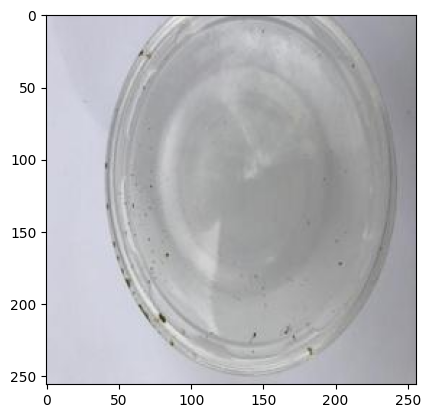

In [81]:
img_path = os.path.join('pictures/train', "9200.jpg")
image = decode_image(img_path)#.float()# / 255.0
plt.imshow(image.permute(1,2,0).cpu().numpy())

In [60]:
class ElementDataset(Dataset):
    def __init__(self, csv, img_dir, transform=None):
        self.df = pd.read_csv(csv)
        self.img_dir = img_dir
        self.transform = transform

        # Map string labels to numbers once at the start using Pandas
        if 'label' in self.df.columns:
            unique_classes = sorted(self.df['label'].unique())
            self.text_to_number = {name: i for i, name in enumerate(unique_classes)}
            self.df['label_idx'] = self.df['label'].map(self.text_to_number)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        # Load and directly normalize the image to float [0.0, 1.0]
        img_path = os.path.join(self.img_dir, f"{row['ID']}.jpg")
        image = decode_image(img_path).float() / 255.0

        if self.transform:
            image = self.transform(image)

        # Get pre-calculated label index, or return -1 for test data
        label_idx = row['label_idx'] if 'label' in self.df.columns else -1

        return image, torch.tensor(label_idx, dtype=torch.long)

In [31]:
!cp -r "/content/drive/MyDrive/Cram School Intermediate 1/Smart_Waste_Classifier/pictures" /content/pictures
!cp -r "/content/drive/MyDrive/Cram School Intermediate 1/Smart_Waste_Classifier/train_data (1).csv" /content
!cp -r "/content/drive/MyDrive/Cram School Intermediate 1/Smart_Waste_Classifier/test_data (1).csv" /content

In [33]:
%cd /content
!ls

/content
 drive	 pictures   sample_data  'test_data (1).csv'  'train_data (1).csv'


In [61]:
train_transforms = T.Compose([
    #T.ConvertImageDtype(torch.float),
    #T.CenterCrop(10),
    T.Resize((224,224)),
    T.RandomHorizontalFlip(0.5),
    T.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225)),
])

test_transforms = T.Compose([
    #T.ConvertImageDtype(torch.float),
    #T.CenterCrop(10),
    T.Resize((224,224)),
    T.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225)),
])

In [62]:
!ls

 drive	    sample_data     'test_data (1).csv'
 pictures   submission.csv  'train_data (1).csv'


In [63]:
train_dataset = ElementDataset(csv='train_data (1).csv', img_dir='pictures/train', transform=train_transforms)
test_dataset = ElementDataset(csv='test_data (1).csv', img_dir='pictures/test', transform=test_transforms)

In [64]:
import multiprocessing
workers = multiprocessing.cpu_count()
BATCH_SIZE = 32
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

label: 5
size: torch.Size([3, 224, 224])


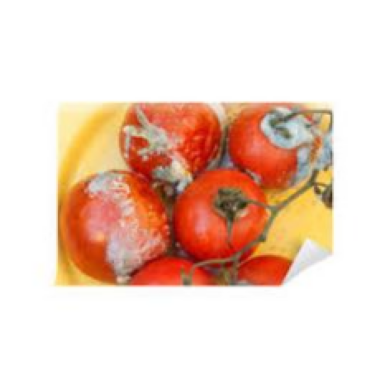

In [65]:
data = next(iter(train_loader))
print(f'label: {data[1][0]}')
print(f'size: {data[0][0].shape}')
img_tensor = data[0][0]

mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
img_denorm = img_tensor * std + mean  # Multiply by std and add the mean to denormalize the image
img_denorm = torch.clamp(img_denorm, 0.0, 1.0)

plt.imshow(img_denorm.permute(1,2,0).cpu().numpy())
plt.axis('off')
plt.show()

In [66]:
from torchvision.models import resnet18

model = resnet18(weights='ResNet18_Weights.DEFAULT')

In [67]:
model.fc = nn.Linear(in_features=512, out_features=len(train_df['label'].unique()))

In [68]:
sum(p.numel() for p in model.parameters())

11179590

In [69]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [70]:
EPOCHS = 3
optim = torch.optim.AdamW(params=model.parameters(), lr=2e-4)
crit = nn.CrossEntropyLoss()

model.to(device)

for epoch in range(EPOCHS):
  running_loss = 0.
  last_loss = 0.

  progress_bar = tqdm(train_loader, total=len(train_loader), desc=f"Epoch {epoch+1}/{EPOCHS}")

  for i, data in enumerate(progress_bar):
    inputs, labels = data
    inputs, labels = inputs.to(device), labels.to(device)

    optim.zero_grad()

    outputs = model(inputs)

    loss = crit(outputs, labels)
    loss.backward()

    optim.step()

    running_loss += loss.item()
    if i % 10 == 0:
      current_avg_loss = running_loss / (i + 1)
      progress_bar.set_postfix({'loss': f"{current_avg_loss:.4f}"})

  epoch_loss = running_loss / len(train_loader)
  print(f"Epoch {epoch+1} finished | Avg loss -> {epoch_loss:.4f}\n")

Epoch 1/3: 100%|██████████| 290/290 [00:54<00:00,  5.33it/s, loss=0.5065]


Epoch 1 finished | Avg loss -> 0.5046



Epoch 2/3: 100%|██████████| 290/290 [00:54<00:00,  5.32it/s, loss=0.2453]


Epoch 2 finished | Avg loss -> 0.2440



Epoch 3/3: 100%|██████████| 290/290 [00:57<00:00,  5.01it/s, loss=0.1565]

Epoch 3 finished | Avg loss -> 0.1560



In [44]:
y_preds = []

with torch.no_grad():
  for i, data in enumerate(tqdm(test_loader, total=len(test_loader))):
    inputs, _ = data
    inputs = inputs.to(device)
    outputs = model(inputs)

    predicted = torch.argmax(outputs, 1)
    y_preds.extend(predicted.cpu().tolist())

100%|██████████| 45/45 [00:06<00:00,  7.11it/s]


In [46]:
y_preds[:5]

[1, 3, 5, 1, 1]

In [52]:
number_to_text = {v: k for k, v in train_dataset.text_to_number.items()}
preds = [number_to_text[p] for p in y_preds]

In [53]:
preds[:5]

['glass', 'paper', 'trash', 'glass', 'glass']

In [54]:
submission = pd.DataFrame({
    'subtaskID': 1,
    'datapointID': test_df['ID'],
    'answer': preds
})

submission.to_csv('submission.csv', index=False)
files.download('submission.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>